In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:.6f}".format

xgb = pd.read_csv("xgboost_results.csv")
keras = pd.read_csv("keras_results.csv")
fastai = pd.read_csv("fastai_results.csv")
print(xgb)

     model     RMSE       R2      MAE  train_time_s
0  XGBoost 0.002080 0.996643 0.000022     65.500116


In [2]:
xgb["precision"] = 1640 / (1640 + 100)
xgb["recall"] = 1640 / (1640 + 3)
xgb["F1"] = 2 * 1640 / (2 * 1640 + 100 + 3)
xgb["ROC_AUC"] = 0.9997050964808136
xgb["PR_AUC"] = 0.9980902588010795

In [3]:
results = pd.concat([xgb, keras, fastai], ignore_index=True)

n_fraud = 1643   # frauds in the test set
results["fraud_caught"] = (results["recall"] * n_fraud).round().astype(int)
results["missed_fraud"] = n_fraud - results["fraud_caught"]
results["false_alarms"] = (results["fraud_caught"] / results["precision"]
                           - results["fraud_caught"]).round().astype(int)

cols = ["model", "precision", "recall", "F1", "ROC_AUC", "PR_AUC",
        "fraud_caught", "missed_fraud", "false_alarms",
        "RMSE", "R2", "MAE", "train_time_s"]
results = results[cols]
results

,model,precision,recall,F1,ROC_AUC,PR_AUC,fraud_caught,missed_fraud,false_alarms,RMSE,R2,MAE,train_time_s
0,XGBoost,0.942529,0.998174,0.969554,0.999705,0.998090,1640,3,100,0.002080,0.996643,0.000022,65.500116
1,Keras MLP,0.990332,0.997565,0.993936,0.999894,0.998615,1639,4,16,0.004365,0.985223,0.000317,60.933025
2,fastai Tabular,0.970885,0.994522,0.982562,0.999006,0.997676,1634,9,49,0.011738,0.893148,0.009665,11.141610


In [4]:
results.to_csv("model_comparison.csv", index=False)

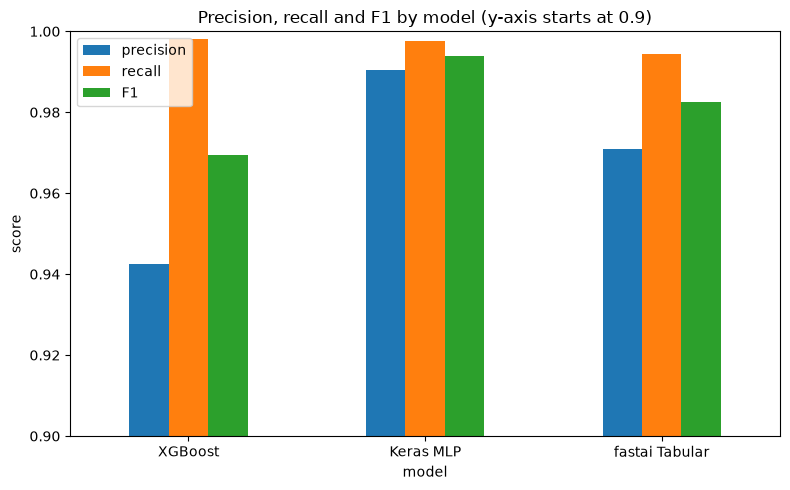

In [5]:
metrics = results.set_index("model")[["precision", "recall", "F1"]]
ax = metrics.plot(kind="bar", figsize=(8, 5), ylim=(0.9, 1.0))
ax.set_title("Precision, recall and F1 by model (y-axis starts at 0.9)")
ax.set_ylabel("score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

Conclusion
All three models detect almost all fraud (recall 0.994–0.998, ROC-AUC above 0.999). At the default 0.5 threshold, the Keras MLP gave the best balance, with the highest precision (0.990) and F1 (0.994): it caught 1,639 of 1,643 frauds with only about 16 false alarms. XGBoost missed the fewest frauds (3) but raised many more false alarms (100), and fastai caught 1,634 frauds with 49 false alarms. XGBoost had the lowest RMSE and MAE and the highest R² (0.9966). fastai trained fastest (11 s), but on a 1 million row sample rather than the full training set.